# 1. Comparação de modelos para risco de aumento
O objetivo é estimar a probabilidade de alta superior a 2% no mês-calendário seguinte. Quatro famílias de classificadores disputam o problema sob o mesmo pré-processamento e o mesmo critério de seleção: regressão logística, árvore de decisão, random forest e gradient boosting por histograma.

In [1]:
from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from basket_price_prediction.config import ROOT, DATASET, SPLITS, FEATURES, MIN_PRECISION, THRESHOLDS
from basket_price_prediction.data import load_data
from basket_price_prediction.preprocessing import prepare_monthly
from basket_price_prediction.features import build_supervised, temporal_split
from basket_price_prediction.training import GRID
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

## 2. Alvo e atributos
Para cada série, o alvo é 1 somente se `(preço t+1 / preço t) - 1 > 0,02`; exatamente 2% é 0. O modelo vê preços em t, t−1 e t−2, variações, média, desvio padrão populacional, mínimo e máximo dessa janela, mês cíclico e identificadores. As três observações devem ser consecutivas. O preço futuro e a variação efetiva são apenas avaliação.

In [2]:
raw=load_data(); monthly,cleaning=prepare_monthly(raw); supervised,report=build_supervised(monthly)
display(pd.Series(report,name="n").to_frame()); display(supervised.head())

,n
monthly_observations,43948
without_next_calendar_month,15108
with_target,28840
with_target_without_history,11838
eligible,17002


,supermarket,product,brand,quantity,month,price_current,records,price_lag_1,price_lag_2,variation_1m,variation_2m,rolling_mean_3m,rolling_std_3m,rolling_min_3m,rolling_max_3m,month_sin,month_cos,target_month,actual_change,target
0,SUP_01,Arroz,Broto Legal,5,2023-08-01,26.09,1,22.90,24.40,0.139301,0.069262,24.463333,1.303082,22.9,26.09,-0.866025,-5.000000e-01,2023-09-01,0.099655,1
1,SUP_01,Arroz,Broto Legal,5,2023-09-01,28.69,1,26.09,22.90,0.099655,0.252838,25.893333,2.367845,22.9,28.69,-1.000000,-1.836970e-16,2023-10-01,-0.041826,0
2,SUP_01,Arroz,Broto Legal,5,2024-03-01,31.99,1,31.80,33.30,0.005975,-0.039339,32.363333,0.666850,31.8,33.30,1.000000,6.123234e-17,2024-04-01,-0.034073,0
3,SUP_01,Arroz,Broto Legal,5,2024-04-01,30.90,1,31.99,31.80,-0.034073,-0.028302,31.563333,0.475418,30.9,31.99,0.866025,-5.000000e-01,2024-05-01,0.097087,1
4,SUP_01,Arroz,Broto Legal,5,2024-05-01,33.90,1,30.90,31.99,0.097087,0.059706,32.263333,1.239901,30.9,33.90,0.500000,-8.660254e-01,2024-06-01,-0.014749,0


### 2.1 Por que o limite é 2%
O corte não é arbitrário. A distribuição das variações mensais mostra uma faixa central de reprecificação rotineira: a mediana é exatamente zero e perto de 44% das transições ficam dentro de ±2%. O limite também é economicamente relevante, já que 2% ao mês compostos equivalem a cerca de 27% ao ano.

,participação
queda > 2%,27.3%
estável em ±2%,43.5%
alta > 2%,29.2%


mediana da variação mensal: 0.0000
2% ao mês compostos em 12 meses: 26.8%


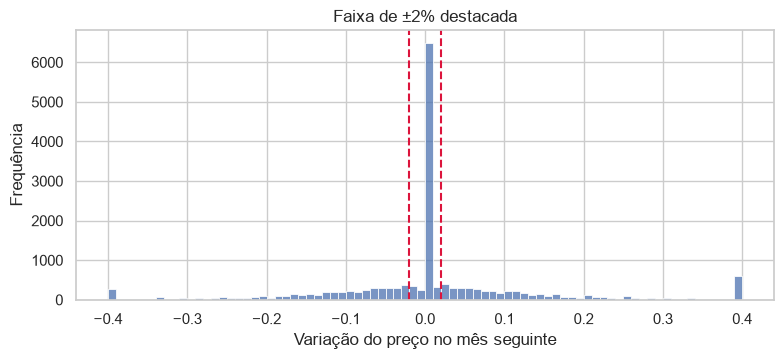

band,n,risk
< -20%,1091,0.644
-20 a -10%,1335,0.501
-10 a -5%,1242,0.403
-5 a -2%,983,0.337
-2 a 0%,565,0.264
preço inalterado,6197,0.190
0 a 2%,583,0.256
2 a 5%,1058,0.305
5 a 10%,1224,0.261
10 a 20%,1290,0.234


Preço inalterado concentra **6,197** observações e tem o **menor** risco da tabela: preço de supermercado é rígido. O risco máximo está na faixa de queda acima de 20%, sinal de reversão à média.

In [3]:
change=supervised.actual_change
faixas=pd.Series({"queda > 2%":(change<-.02).mean(),"estável em ±2%":(change.abs()<=.02).mean(),"alta > 2%":(change>.02).mean()},name="participação")
display(faixas.to_frame().style.format("{:.1%}"))
print("mediana da variação mensal: %.4f" % change.median())
print("2%% ao mês compostos em 12 meses: %.1f%%" % (100*(1.02**12-1)))
plt.figure(figsize=(9,3.5)); sns.histplot(change.clip(-.4,.4),bins=80)
for x in (-.02,.02): plt.axvline(x,color="crimson",ls="--")
plt.xlabel("Variação do preço no mês seguinte"); plt.ylabel("Frequência"); plt.title("Faixa de ±2% destacada"); plt.show()

from basket_price_prediction.evaluation import risk_by_variation_band
perfil=risk_by_variation_band(supervised)
display(perfil.style.format({"risk":"{:.3f}"}).hide(axis="index"))
display(Markdown(f"Preço inalterado concentra **{perfil.set_index('band').loc['preço inalterado','n']:,}** observações e tem o **menor** risco da tabela: preço de supermercado é rígido. O risco máximo está na faixa de queda acima de 20%, sinal de reversão à média."))

## 3. Partição cronológica e desequilíbrio
Os limites se referem ao **mês-alvo**; as características vêm até o mês anterior. Treino termina em dezembro/2024, validação cobre janeiro–agosto/2025 e teste setembro/2025–agosto/2026.

In [4]:
parts=temporal_split(supervised,SPLITS)
display(pd.DataFrame({k:{"n":len(v),"positivos":int(v.target.sum()),"prevalência":v.target.mean(),"primeiro alvo":v.target_month.min(),"último alvo":v.target_month.max()} for k,v in parts.items()}).T)

,n,positivos,prevalência,primeiro alvo,último alvo
train,10268,3068,0.298792,2022-12-01 00:00:00,2024-12-01 00:00:00
validation,3554,970,0.272932,2025-01-01 00:00:00,2025-08-01 00:00:00
test,3180,919,0.288994,2025-09-01 00:00:00,2026-08-01 00:00:00


## 4. As famílias comparadas e o critério
`ColumnTransformer` ajusta codificação one-hot somente no treino, aceitando categorias novas; a escala numérica é aplicada apenas à família linear, porque árvores são invariantes a transformação monotônica dos atributos.

O critério de seleção é único e vale para todas as famílias: **maior F1 na validação entre os candidatos com precisão de pelo menos 0,35**, com desempate por precisão, menor limiar e nome do algoritmo. Se nenhum candidato atingir o piso, usa-se o maior F1 e registra-se a exceção. O mesmo critério é reaplicado dentro de cada família para montar a comparação, de modo que nenhuma delas seja avaliada por uma régua mais favorável.

O F1 foi usado para combinar precisão e recall em uma única métrica. O piso de 35% restringe a seleção a candidatos com precisão mínima na validação, quando há candidatos elegíveis. Nesta execução, o maior F1 da grade já era da random forest, com precisão de 40,2% na validação. Aplicar o piso manteve a mesma escolha.

In [5]:
grade=pd.DataFrame([{"família":k,"configurações":len(v),"exemplo de configuração":v[0]} for k,v in GRID.items()])
display(grade)
print("Total: %d configurações x %d limiares = %d candidatos avaliados na validação" % (grade.configurações.sum(),len(THRESHOLDS),grade.configurações.sum()*len(THRESHOLDS)))
print("Piso de precisão exigido na seleção: %.2f" % MIN_PRECISION)

,família,configurações,exemplo de configuração
0,logistic_regression,6,"{'C': 0.1, 'class_weight': None}"
1,decision_tree,6,"{'max_depth': 3, 'class_weight': None}"
2,random_forest,8,"{'max_depth': None, 'min_samples_leaf': 5, 'cl..."
3,gradient_boosting,4,"{'learning_rate': 0.05, 'class_weight': None}"


Total: 24 configurações x 17 limiares = 408 candidatos avaliados na validação
Piso de precisão exigido na seleção: 0.35


## 5. Treinamento intencional e artefatos
Para gerar uma execução nova, defina `RUN_TRAINING = True` ou execute o notebook com `BASKET_TRAIN=1`. Cada execução cria um diretório único; por padrão a reabertura não treina. A configuração escolhida é reajustada em treino + validação e só então o teste é consultado. Predições de validação são do modelo anterior ao reajuste. Uma execução completa leva cerca de 100 segundos.

In [6]:
import os
from basket_price_prediction.experiments import run_training, load_experiment
RUN_TRAINING = os.environ.get("BASKET_TRAIN", "0") == "1"
if RUN_TRAINING:
    experiment_path=run_training()
    print("Experimento concluído:",experiment_path)
else:
    print("Treinamento não solicitado. Defina RUN_TRAINING=True para criar uma execução.")

Experimento concluído: C:\Users\gcatt\basket-price-analysis\runs\results\20261126_010701_449938_2a01bd42_comparacao


## 6. Evidências da seleção
A tabela de candidatos vem exclusivamente da validação. A comparação entre famílias mostra o melhor candidato de cada uma sob o mesmo critério: é essa coluna que decide a escolha, e não qualquer métrica de teste.

In [7]:
if RUN_TRAINING:
    experiment=load_experiment(experiment_path)
    display(pd.Series(experiment["config"]["selection"],name="seleção").to_frame())
    comparacao=experiment["comparison"]
    display(comparacao[["algorithm","params","threshold","precision_validation","recall_validation","f1_validation"]].sort_values("f1_validation",ascending=False))
    display(pd.read_csv(experiment_path/"reports"/"validation_candidates.csv").sort_values("f1",ascending=False).head(10))
    display(pd.Series(experiment["metrics"]["validation_before_refit"],name="validação antes do reajuste").to_frame())

,seleção
algorithm,random_forest
params,"{'class_weight': None, 'max_depth': 10, 'min_s..."
threshold,0.25
criterion,maior F1 na validação com precisão >= 0.35; de...
searched_algorithms,"[decision_tree, gradient_boosting, logistic_re..."
fits,24
candidate_rows,408
fallback_no_candidate_met_precision,False


,algorithm,params,threshold,precision_validation,recall_validation,f1_validation
3,random_forest,"{""class_weight"": null, ""max_depth"": 10, ""min_s...",0.25,0.401821,0.727835,0.517785
1,gradient_boosting,"{""class_weight"": null, ""learning_rate"": 0.05}",0.25,0.403902,0.576289,0.474936
0,decision_tree,"{""class_weight"": null, ""max_depth"": 10}",0.25,0.392458,0.579381,0.467943
2,logistic_regression,"{""C"": 10.0, ""class_weight"": null}",0.25,0.363208,0.555670,0.439283


,algorithm,params,threshold,precision,recall,f1,roc_auc,average_precision
275,random_forest,"{""class_weight"": null, ""max_depth"": 10, ""min_s...",0.25,0.401821,0.727835,0.517785,0.714822,0.501724
295,random_forest,"{""class_weight"": ""balanced_subsample"", ""max_de...",0.40,0.374286,0.810309,0.512052,0.710021,0.498343
309,random_forest,"{""class_weight"": null, ""max_depth"": 10, ""min_s...",0.25,0.390710,0.737113,0.510714,0.705403,0.494182
329,random_forest,"{""class_weight"": ""balanced_subsample"", ""max_de...",0.40,0.360304,0.830928,0.502650,0.706264,0.493210
206,random_forest,"{""class_weight"": null, ""max_depth"": null, ""min...",0.20,0.359439,0.818557,0.499528,0.698649,0.484899
330,random_forest,"{""class_weight"": ""balanced_subsample"", ""max_de...",0.45,0.412239,0.631959,0.498982,0.706264,0.493210
296,random_forest,"{""class_weight"": ""balanced_subsample"", ""max_de...",0.45,0.417730,0.607216,0.494958,0.710021,0.498343
241,random_forest,"{""class_weight"": null, ""max_depth"": null, ""min...",0.25,0.389881,0.675258,0.494340,0.700707,0.491080
240,random_forest,"{""class_weight"": null, ""max_depth"": null, ""min...",0.20,0.342657,0.858763,0.489856,0.700707,0.491080
260,random_forest,"{""class_weight"": ""balanced_subsample"", ""max_de...",0.35,0.345955,0.828866,0.488160,0.691531,0.481786


,validação antes do reajuste
n,3554
positives,970
negatives,2584
accuracy,0.629994
precision,0.401821
recall,0.727835
f1,0.517785
balanced_accuracy,0.660551
roc_auc,0.714822
average_precision,0.501724


A família vencedora é decidida por evidência, e não por hipótese inicial. O ajuste bem-sucedido, por si só, não demonstra utilidade preditiva: consulte o teste independente, os intervalos de confiança, os falsos alarmes, a estabilidade temporal e as limitações no notebook seguinte.